 Healthcare Clinical Data Analysis

Data Cleaning

In [1]:
#importing libraries

import pandas as pd                           
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#load the dataset
df = pd.read_csv("Clinical_Dataset_Raw.csv")  


In [3]:
#number of rows and columns
print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(13214, 22)


In [4]:
#first 5 rows and columns of dataset
df.head()


,clinical_record_id,encounter_id,patient_id,primary_diagnosis_code,primary_diagnosis_name,disease_category,disease_severity,secondary_diagnosis_code,systolic_bp_mmhg,diastolic_bp_mmhg,...,temperature_celsius,spo2_percent,blood_glucose_mg_dl,serum_creatinine_mg_dl,hemoglobin_g_dl,white_blood_cell_count,primary_procedure_code,primary_procedure_name,procedure_complexity,hospital_acquired_infection
0,CLN-100001,ENC-100001,PAT-10001,N39.0,Urinary Tract Infection with Pyelonephritis,Renal,Mild,E78.5,119.7,78.9,...,36.6,99.6,116.2,1.17,NaN,4.5,99221,Inpatient Bladder Management & Culture Evaluation,NaN,0
1,CLN-100002,ENC-100002,PAT-10001,J44.1,COPD with Acute Exacerbation,Respiratory,Moderate,N18.3,118.5,86.2,...,37.2,97.9,98.0,0.71,14.4,6.8,94660,Continuous Positive Airway Pressure (CPAP) Man...,Minor,0
2,CLN-100003,ENC-100003,PAT-10001,I50.9,"Congestive Heart Failure, Unspecified",Cardiovascular,Severe,E78.5,129.0,87.2,...,36.7,98.8,118.5,2.89,15.1,25.9,99223,Comprehensive Inpatient Medical Management,NaN,0
3,CLN-100004,ENC-100004,PAT-10002,I21.9,Acute Myocardial Infarction,Cardiovascular,Severe,I10,150.8,102.0,...,37.0,98.5,92.8,1.46,13.9,22.3,92928,Percutaneous Coronary Angioplasty with Stent,Major,0
4,CLN-100005,ENC-100005,PAT-10002,J18.9,Community-Acquired Pneumonia,Respiratory,Mild,E66.0,120.9,81.4,...,36.7,98.6,66.5,0.83,NaN,7.2,99223,Inpatient Pulmonary Evaluation & Sputum Culture,NaN,1


In [5]:
#las 5 rows and columns of dataset
df.tail()

,clinical_record_id,encounter_id,patient_id,primary_diagnosis_code,primary_diagnosis_name,disease_category,disease_severity,secondary_diagnosis_code,systolic_bp_mmhg,diastolic_bp_mmhg,...,temperature_celsius,spo2_percent,blood_glucose_mg_dl,serum_creatinine_mg_dl,hemoglobin_g_dl,white_blood_cell_count,primary_procedure_code,primary_procedure_name,procedure_complexity,hospital_acquired_infection
13209,CLN-113210,ENC-113210,PAT-14998,I50.9,"Congestive Heart Failure, Unspecified",Cardiovascular,Severe,E78.5,126.0,84.3,...,37.3,98.5,113.7,1.20,16.1,11.0,99223,Comprehensive Inpatient Medical Management,NaN,0
13210,CLN-113211,ENC-113211,PAT-14998,I21.9,Acute Myocardial Infarction,Cardiovascular,Severe,N18.3,148.3,97.0,...,36.5,99.0,111.1,1.27,14.1,16.7,92928,Percutaneous Coronary Angioplasty with Stent,Major,0
13211,CLN-113212,ENC-113212,PAT-14999,N39.0,Urinary Tract Infection with Pyelonephritis,Renal,Moderate,NaN,113.3,79.8,...,37.4,95.6,96.7,1.00,13.4,9.2,99221,Inpatient Bladder Management & Culture Evaluation,NaN,0
13212,CLN-113213,ENC-113213,PAT-15000,I50.9,"Congestive Heart Failure, Unspecified",Cardiovascular,Moderate,NaN,150.7,105.4,...,36.6,99.1,113.4,1.03,11.7,6.6,99223,Comprehensive Inpatient Medical Management,NaN,0
13213,CLN-113214,ENC-113214,PAT-15000,K80.2,Calculus of Gallbladder (Cholelithiasis),Gastrointestinal,Moderate,I10,101.5,69.9,...,36.8,98.3,87.1,0.91,11.2,4.8,47562,Laparoscopic Cholecystectomy,Moderate,0


In [6]:
#column details
df.columns

Index(['clinical_record_id', 'encounter_id', 'patient_id',
       'primary_diagnosis_code', 'primary_diagnosis_name', 'disease_category',
       'disease_severity', 'secondary_diagnosis_code', 'systolic_bp_mmhg',
       'diastolic_bp_mmhg', 'heart_rate_bpm', 'respiratory_rate_bpm',
       'temperature_celsius', 'spo2_percent', 'blood_glucose_mg_dl',
       'serum_creatinine_mg_dl', 'hemoglobin_g_dl', 'white_blood_cell_count',
       'primary_procedure_code', 'primary_procedure_name',
       'procedure_complexity', 'hospital_acquired_infection'],
      dtype='object')

In [7]:
#datset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13214 entries, 0 to 13213
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   clinical_record_id           13214 non-null  object 
 1   encounter_id                 13214 non-null  object 
 2   patient_id                   13214 non-null  object 
 3   primary_diagnosis_code       13214 non-null  object 
 4   primary_diagnosis_name       13214 non-null  object 
 5   disease_category             13214 non-null  object 
 6   disease_severity             13214 non-null  object 
 7   secondary_diagnosis_code     12423 non-null  object 
 8   systolic_bp_mmhg             13214 non-null  float64
 9   diastolic_bp_mmhg            13214 non-null  float64
 10  heart_rate_bpm               13214 non-null  float64
 11  respiratory_rate_bpm         13214 non-null  float64
 12  temperature_celsius          13214 non-null  float64
 13  spo2_percent    

In [8]:
#statistical summary of numerical columns.
df.describe()

,systolic_bp_mmhg,diastolic_bp_mmhg,heart_rate_bpm,respiratory_rate_bpm,temperature_celsius,spo2_percent,blood_glucose_mg_dl,serum_creatinine_mg_dl,hemoglobin_g_dl,white_blood_cell_count,primary_procedure_code,hospital_acquired_infection
count,13214.000000,13214.000000,13214.000000,13214.000000,13214.000000,12459.000000,12391.000000,12459.000000,12540.000000,12412.000000,13214.000000,13214.000000
mean,122.211291,80.818571,80.563244,17.499213,36.938527,96.849924,112.942652,1.592064,13.081770,11.124251,72073.653020,0.027395
std,19.055208,12.427099,16.990314,4.131009,0.728502,3.439451,39.564979,0.842431,2.030597,5.733485,30525.204275,0.163238
min,68.000000,45.000000,55.000000,12.000000,36.000000,77.900000,65.000000,0.500000,6.500000,3.200000,27236.000000,0.000000
25%,112.900000,74.100000,69.700000,15.000000,36.500000,96.600000,91.300000,0.980000,11.800000,6.900000,36556.000000,0.000000
50%,122.300000,80.800000,76.800000,16.500000,36.800000,97.800000,104.200000,1.290000,13.300000,8.700000,92928.000000,0.000000
75%,131.600000,87.600000,85.800000,18.400000,37.100000,98.800000,119.000000,2.010000,14.500000,15.500000,99222.000000,0.000000
max,197.800000,120.000000,155.000000,39.200000,40.400000,100.000000,349.200000,7.500000,17.500000,31.000000,99223.000000,1.000000


In [9]:
#Checking null values
missing_values = df.isnull().sum()

print(missing_values)

clinical_record_id                0
encounter_id                      0
patient_id                        0
primary_diagnosis_code            0
primary_diagnosis_name            0
disease_category                  0
disease_severity                  0
secondary_diagnosis_code        791
systolic_bp_mmhg                  0
diastolic_bp_mmhg                 0
heart_rate_bpm                    0
respiratory_rate_bpm              0
temperature_celsius               0
spo2_percent                    755
blood_glucose_mg_dl             823
serum_creatinine_mg_dl          755
hemoglobin_g_dl                 674
white_blood_cell_count          802
primary_procedure_code            0
primary_procedure_name            0
procedure_complexity           5654
hospital_acquired_infection       0
dtype: int64


In [10]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage[missing_percentage > 0].round(2))


secondary_diagnosis_code     5.99
spo2_percent                 5.71
blood_glucose_mg_dl          6.23
serum_creatinine_mg_dl       5.71
hemoglobin_g_dl              5.10
white_blood_cell_count       6.07
procedure_complexity        42.79
dtype: float64


In [11]:
missing_columns = df.columns[df.isnull().any()]

print("Columns with missing values:")
print(missing_columns)

Columns with missing values:
Index(['secondary_diagnosis_code', 'spo2_percent', 'blood_glucose_mg_dl',
       'serum_creatinine_mg_dl', 'hemoglobin_g_dl', 'white_blood_cell_count',
       'procedure_complexity'],
      dtype='object')


In [12]:
df.loc[
    df['procedure_complexity'].isnull(),
    'primary_procedure_name'
].value_counts().head(10)

primary_procedure_name
Inpatient Pulmonary Evaluation & Sputum Culture      1695
Inpatient Bladder Management & Culture Evaluation    1435
Inpatient Glycemic Stabilization & Consult           1291
Comprehensive Inpatient Medical Management            920
Pediatric Inpatient Evaluation & Nebulizer Care       313
Name: count, dtype: int64

In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

print(missing_values)

                             Missing Count  Missing Percentage
clinical_record_id                       0            0.000000
encounter_id                             0            0.000000
patient_id                               0            0.000000
primary_diagnosis_code                   0            0.000000
primary_diagnosis_name                   0            0.000000
disease_category                         0            0.000000
disease_severity                         0            0.000000
secondary_diagnosis_code               791            5.986075
systolic_bp_mmhg                         0            0.000000
diastolic_bp_mmhg                        0            0.000000
heart_rate_bpm                           0            0.000000
respiratory_rate_bpm                     0            0.000000
temperature_celsius                      0            0.000000
spo2_percent                           755            5.713637
blood_glucose_mg_dl                    823            6

In [15]:
print(df['procedure_complexity'].value_counts(dropna=False))

procedure_complexity
NaN                5654
Moderate           3270
Major              2612
High-Complexity     875
Minor               803
Name: count, dtype: int64


In [16]:
missing_procedures = df[df['procedure_complexity'].isnull()]

print("Number of missing complexity records:",
      len(missing_procedures))

print("\nProcedure names in missing records:")

print(missing_procedures['primary_procedure_name'].value_counts())

print("\nProcedure codes in missing records:")

print(missing_procedures['primary_procedure_code'].value_counts())

Number of missing complexity records: 5654

Procedure names in missing records:
primary_procedure_name
Inpatient Pulmonary Evaluation & Sputum Culture      1695
Inpatient Bladder Management & Culture Evaluation    1435
Inpatient Glycemic Stabilization & Consult           1291
Comprehensive Inpatient Medical Management            920
Pediatric Inpatient Evaluation & Nebulizer Care       313
Name: count, dtype: int64

Procedure codes in missing records:
primary_procedure_code
99223    2615
99221    1748
99222    1291
Name: count, dtype: int64


In [17]:
print(pd.crosstab(
    df['primary_procedure_code'],
    df['procedure_complexity'],
    dropna=False
))

procedure_complexity    High-Complexity  Major  Minor  Moderate   NaN
primary_procedure_code                                               
27236                                 0    636      0         0     0
27447                                 0    839      0         0     0
32663                               875      0      0         0     0
36556                                 0      0      0      1665     0
47562                                 0      0      0      1303     0
59400                                 0      0      0       302     0
92928                                 0   1137      0         0     0
94660                                 0      0    803         0     0
99221                                 0      0      0         0  1748
99222                                 0      0      0         0  1291
99223                                 0      0      0         0  2615


In [18]:
df['procedure_complexity'] = df['procedure_complexity'].fillna('Not Applicable')

In [19]:
print(df['procedure_complexity'].value_counts())

procedure_complexity
Not Applicable     5654
Moderate           3270
Major              2612
High-Complexity     875
Minor               803
Name: count, dtype: int64


In [20]:
numeric_cols = [
    'spo2_percent',
    'blood_glucose_mg_dl',
    'serum_creatinine_mg_dl',
    'hemoglobin_g_dl',
    'white_blood_cell_count'
]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

In [21]:
print(df[numeric_cols].isnull().sum())

spo2_percent              0
blood_glucose_mg_dl       0
serum_creatinine_mg_dl    0
hemoglobin_g_dl           0
white_blood_cell_count    0
dtype: int64


In [22]:
df['secondary_diagnosis_code'] = df['secondary_diagnosis_code'].fillna(
    'No Secondary Diagnosis Recorded'
)

In [23]:
print(df['secondary_diagnosis_code'].isnull().sum())

0


In [24]:
print(df.isnull().sum())        

clinical_record_id             0
encounter_id                   0
patient_id                     0
primary_diagnosis_code         0
primary_diagnosis_name         0
disease_category               0
disease_severity               0
secondary_diagnosis_code       0
systolic_bp_mmhg               0
diastolic_bp_mmhg              0
heart_rate_bpm                 0
respiratory_rate_bpm           0
temperature_celsius            0
spo2_percent                   0
blood_glucose_mg_dl            0
serum_creatinine_mg_dl         0
hemoglobin_g_dl                0
white_blood_cell_count         0
primary_procedure_code         0
primary_procedure_name         0
procedure_complexity           0
hospital_acquired_infection    0
dtype: int64


In [25]:
print(df.dtypes) #checking datatype

clinical_record_id              object
encounter_id                    object
patient_id                      object
primary_diagnosis_code          object
primary_diagnosis_name          object
disease_category                object
disease_severity                object
secondary_diagnosis_code        object
systolic_bp_mmhg               float64
diastolic_bp_mmhg              float64
heart_rate_bpm                 float64
respiratory_rate_bpm           float64
temperature_celsius            float64
spo2_percent                   float64
blood_glucose_mg_dl            float64
serum_creatinine_mg_dl         float64
hemoglobin_g_dl                float64
white_blood_cell_count         float64
primary_procedure_code           int64
primary_procedure_name          object
procedure_complexity            object
hospital_acquired_infection      int64
dtype: object


In [26]:
df['primary_procedure_code'] = df['primary_procedure_code'].astype(str)    

In [27]:
print(df['primary_procedure_code'].dtype)

object


In [28]:
clinical_cols = [
    'systolic_bp_mmhg',
    'diastolic_bp_mmhg',
    'heart_rate_bpm',
    'respiratory_rate_bpm',
    'temperature_celsius',
    'spo2_percent',
    'blood_glucose_mg_dl',
    'serum_creatinine_mg_dl',
    'hemoglobin_g_dl',
    'white_blood_cell_count'
]

print(df[clinical_cols].agg(['min', 'max']).T)

                         min    max
systolic_bp_mmhg        68.0  197.8
diastolic_bp_mmhg       45.0  120.0
heart_rate_bpm          55.0  155.0
respiratory_rate_bpm    12.0   39.2
temperature_celsius     36.0   40.4
spo2_percent            77.9  100.0
blood_glucose_mg_dl     65.0  349.2
serum_creatinine_mg_dl   0.5    7.5
hemoglobin_g_dl          6.5   17.5
white_blood_cell_count   3.2   31.0


In [29]:
#detecting outliers using the IQR (Interquartile Range) method.
for col in clinical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outlier_percentage = (len(outliers) / len(df)) * 100

    print(f"\n{col}")
    print("Lower limit:", round(lower, 2))
    print("Upper limit:", round(upper, 2))
    print("Outlier count:", len(outliers))
    print("Outlier percentage:", round(outlier_percentage, 2), "%")
    print("Normal values:", len(df) - len(outliers)) 


systolic_bp_mmhg
Lower limit: 84.85
Upper limit: 159.65
Outlier count: 1115
Outlier percentage: 8.44 %
Normal values: 12099

diastolic_bp_mmhg
Lower limit: 53.85
Upper limit: 107.85
Outlier count: 643
Outlier percentage: 4.87 %
Normal values: 12571

heart_rate_bpm
Lower limit: 45.55
Upper limit: 109.95
Outlier count: 1158
Outlier percentage: 8.76 %
Normal values: 12056

respiratory_rate_bpm
Lower limit: 9.9
Upper limit: 23.5
Outlier count: 1209
Outlier percentage: 9.15 %
Normal values: 12005

temperature_celsius
Lower limit: 35.6
Upper limit: 38.0
Outlier count: 1172
Outlier percentage: 8.87 %
Normal values: 12042

spo2_percent
Lower limit: 93.7
Upper limit: 101.7
Outlier count: 1452
Outlier percentage: 10.99 %
Normal values: 11762

blood_glucose_mg_dl
Lower limit: 54.45
Upper limit: 155.65
Outlier count: 1135
Outlier percentage: 8.59 %
Normal values: 12079

serum_creatinine_mg_dl
Lower limit: -0.42
Upper limit: 3.38
Outlier count: 519
Outlier percentage: 3.93 %
Normal values: 12695



In [30]:
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


clinical_record_id
clinical_record_id
CLN-100001    1
CLN-100002    1
CLN-100003    1
CLN-100004    1
CLN-100005    1
             ..
CLN-113210    1
CLN-113211    1
CLN-113212    1
CLN-113213    1
CLN-113214    1
Name: count, Length: 13214, dtype: int64

encounter_id
encounter_id
ENC-100001    1
ENC-100002    1
ENC-100003    1
ENC-100004    1
ENC-100005    1
             ..
ENC-113210    1
ENC-113211    1
ENC-113212    1
ENC-113213    1
ENC-113214    1
Name: count, Length: 13214, dtype: int64

patient_id
patient_id
PAT-14952    6
PAT-12165    6
PAT-14976    6
PAT-12169    6
PAT-14993    6
            ..
PAT-14978    1
PAT-14977    1
PAT-14968    1
PAT-14964    1
PAT-10035    1
Name: count, Length: 5000, dtype: int64

primary_diagnosis_code
primary_diagnosis_code
J18.9    1695
A41.9    1665
N39.0    1435
K80.2    1303
E11.9    1291
I21.9    1137
I50.9     920
C34.9     875
M17.9     839
J44.1     803
S72.0     636
J20.9     313
O80       302
Name: count, dtype: int64

primary_diagnosi

In [31]:
for col in ['disease_category', 'disease_severity',
            'procedure_complexity', 'hospital_acquired_infection']:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


disease_category:
disease_category
Respiratory         2498
Cardiovascular      2057
Infectious          1665
Renal               1435
Gastrointestinal    1303
Endocrine           1291
Oncology             875
Musculoskeletal      839
Trauma               636
Pediatrics           313
Obstetrics           302
Name: count, dtype: int64

disease_severity:
disease_severity
Moderate    5104
Severe      3436
Mild        3181
Critical    1493
Name: count, dtype: int64

procedure_complexity:
procedure_complexity
Not Applicable     5654
Moderate           3270
Major              2612
High-Complexity     875
Minor               803
Name: count, dtype: int64

hospital_acquired_infection:
hospital_acquired_infection
0    12852
1      362
Name: count, dtype: int64


In [32]:
print(df.isnull().sum())   #checking null values

clinical_record_id             0
encounter_id                   0
patient_id                     0
primary_diagnosis_code         0
primary_diagnosis_name         0
disease_category               0
disease_severity               0
secondary_diagnosis_code       0
systolic_bp_mmhg               0
diastolic_bp_mmhg              0
heart_rate_bpm                 0
respiratory_rate_bpm           0
temperature_celsius            0
spo2_percent                   0
blood_glucose_mg_dl            0
serum_creatinine_mg_dl         0
hemoglobin_g_dl                0
white_blood_cell_count         0
primary_procedure_code         0
primary_procedure_name         0
procedure_complexity           0
hospital_acquired_infection    0
dtype: int64


In [33]:
df.to_csv('Clinical_Dataset_Cleaned.csv', index=False)

In [34]:
import os
print(os.path.exists('Clinical_Dataset_Cleaned.csv'))   #Saving cleaned Dataset

True


Exploratory Data Analysis (EDA)

In [35]:
# descriptive statistics for numerical columns
print(df.describe())

       systolic_bp_mmhg  diastolic_bp_mmhg  heart_rate_bpm  \
count      13214.000000       13214.000000    13214.000000   
mean         122.211291          80.818571       80.563244   
std           19.055208          12.427099       16.990314   
min           68.000000          45.000000       55.000000   
25%          112.900000          74.100000       69.700000   
50%          122.300000          80.800000       76.800000   
75%          131.600000          87.600000       85.800000   
max          197.800000         120.000000      155.000000   

       respiratory_rate_bpm  temperature_celsius  spo2_percent  \
count          13214.000000         13214.000000  13214.000000   
mean              17.499213            36.938527     96.904208   
std                4.131009             0.728502      3.347012   
min               12.000000            36.000000     77.900000   
25%               15.000000            36.500000     96.700000   
50%               16.500000            36.800

In [36]:
# Count the number of records in each disease category
disease_counts = df['disease_category'].value_counts()

# Display the category counts
print(disease_counts)

disease_category
Respiratory         2498
Cardiovascular      2057
Infectious          1665
Renal               1435
Gastrointestinal    1303
Endocrine           1291
Oncology             875
Musculoskeletal      839
Trauma               636
Pediatrics           313
Obstetrics           302
Name: count, dtype: int64


1.Disease Category Distribution
Identify the distribution of patient records across different disease categories.


Barchart

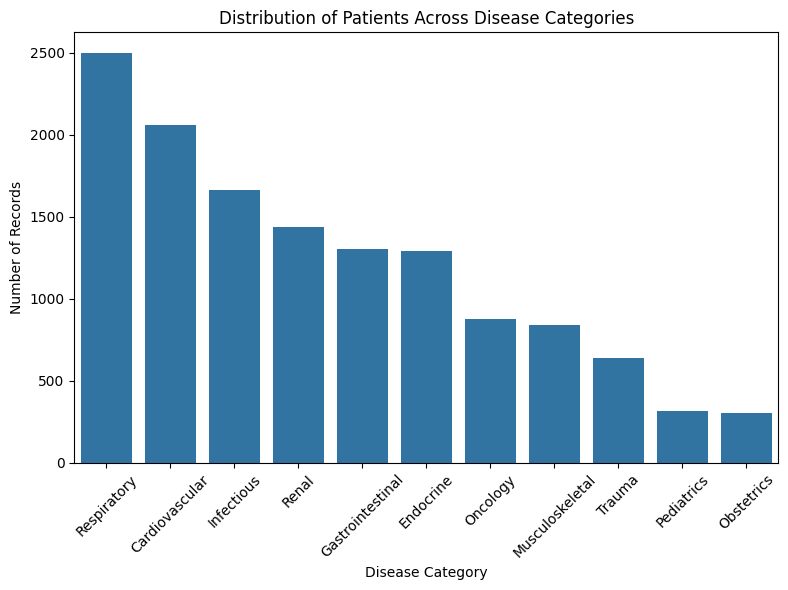

In [37]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure
plt.figure(figsize=(8, 6))

# Create bar chart
sns.barplot(
    x=disease_counts.index,
    y=disease_counts.values
)

# Add chart title and labels
plt.title('Distribution of Patients Across Disease Categories')
plt.xlabel('Disease Category')
plt.ylabel('Number of Records')

# Rotate category labels
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()

2.Disease Severity Distribution
To Understand how patient records are distributed across different disease severity levels.

In [38]:
# Count records for each disease severity level
severity_counts = df['disease_severity'].value_counts()

# Display the results
print(severity_counts)

disease_severity
Moderate    5104
Severe      3436
Mild        3181
Critical    1493
Name: count, dtype: int64


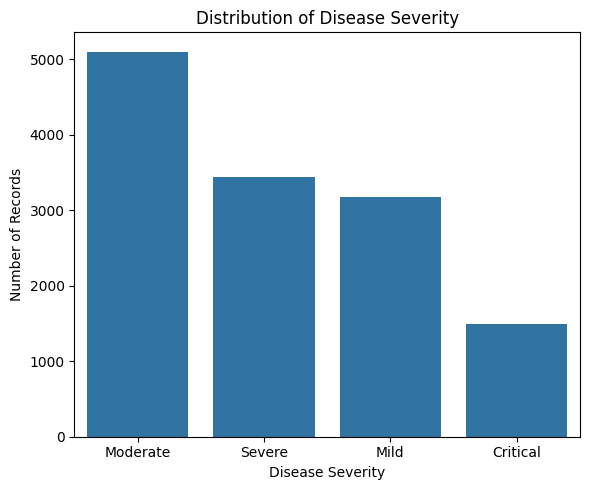

In [39]:
# Create a figure
plt.figure(figsize=(6, 5))

# Create bar chart
sns.barplot(
    x=severity_counts.index,
    y=severity_counts.values
)

# Add title and axis labels
plt.title('Distribution of Disease Severity')
plt.xlabel('Disease Severity')
plt.ylabel('Number of Records')

# Display the chart
plt.tight_layout()
plt.show()

The dataset contains more Moderate and Severe cases than Mild and Critical cases. Moderate cases represent the largest group, while Critical cases are the smallest group.

3.Hospital-Acquired Infection Analysis
 To Determine how many records indicate hospital-acquired infections and how many do not

In [40]:
# Count infection and non-infection records
infection_counts = df['hospital_acquired_infection'].value_counts()

# Display the counts
print(infection_counts)

hospital_acquired_infection
0    12852
1      362
Name: count, dtype: int64


Pie Chart

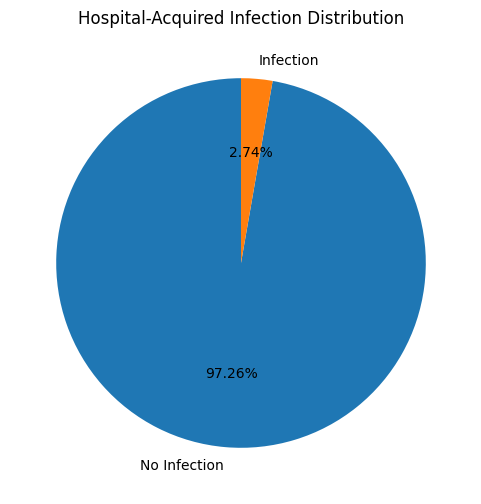

In [41]:
# Define labels for the pie chart
labels = ['No Infection', 'Infection']

# Create pie chart
plt.figure(figsize=(6, 6))

plt.pie(
    infection_counts,
    labels=labels,
    autopct='%1.2f%%',
    startangle=90
)

# Add chart title
plt.title('Hospital-Acquired Infection Distribution')

# Display the chart
plt.show()

The majority of records (97.26%) indicate no hospital-acquired infection, while 2.74% indicate an infection.

4.Systolic Blood Pressure Analysis
To Understand the distribution and variation of systolic blood pressure measurements among patients.

In [42]:
# Calculate statistical summary of systolic blood pressure
print(df['systolic_bp_mmhg'].describe())

count    13214.000000
mean       122.211291
std         19.055208
min         68.000000
25%        112.900000
50%        122.300000
75%        131.600000
max        197.800000
Name: systolic_bp_mmhg, dtype: float64


Histogram


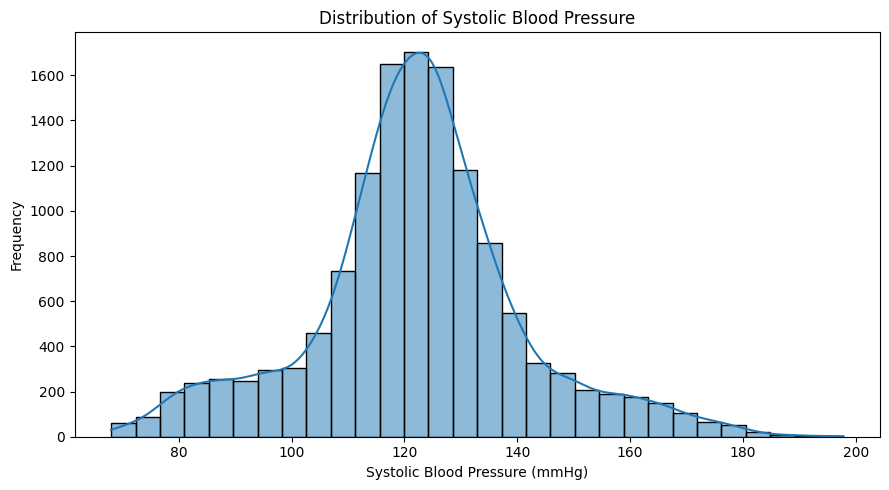

In [43]:
# Create a figure
plt.figure(figsize=(9, 5))

# Plot histogram
sns.histplot(
    df['systolic_bp_mmhg'],
    bins=30,
    kde=True
)

# Add title and labels
plt.title('Distribution of Systolic Blood Pressure')
plt.xlabel('Systolic Blood Pressure (mmHg)')
plt.ylabel('Frequency')

# Display chart
plt.tight_layout()
plt.show()

The histogram helps us understand the spread and frequency of systolic blood pressure measurements. Most observations are concentrated around the central range, with some higher and lower values.

5.Diastolic Blood Pressure Analysis
To Examine the distribution and variation of diastolic blood pressure measurements.

In [44]:
# Calculate descriptive statistics for diastolic blood pressure
print(df['diastolic_bp_mmhg'].describe())

count    13214.000000
mean        80.818571
std         12.427099
min         45.000000
25%         74.100000
50%         80.800000
75%         87.600000
max        120.000000
Name: diastolic_bp_mmhg, dtype: float64


Histogram

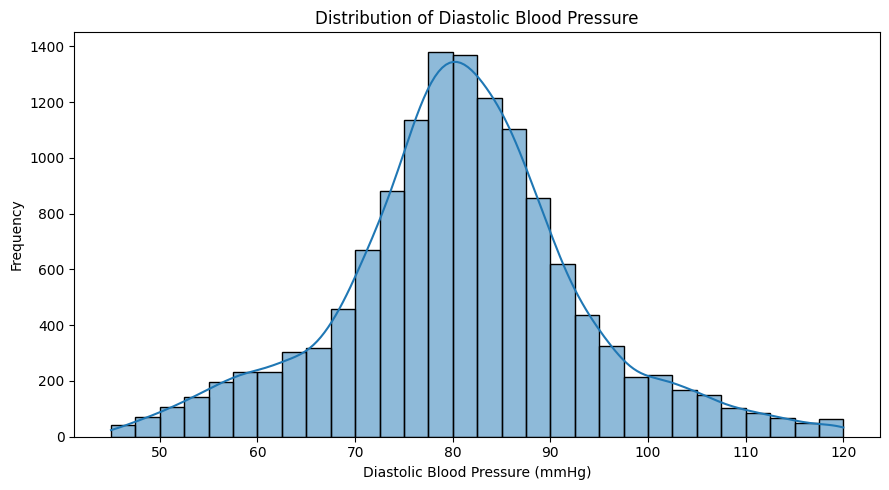

In [45]:
# Create a figure
plt.figure(figsize=(9, 5))

# Create histogram with density curve
sns.histplot(
    df['diastolic_bp_mmhg'],
    bins=30,
    kde=True
)

# Add chart title and axis labels
plt.title('Distribution of Diastolic Blood Pressure')
plt.xlabel('Diastolic Blood Pressure (mmHg)')
plt.ylabel('Frequency')

# Display chart
plt.tight_layout()
plt.show()

The mean and median are nearly equal, indicating that the measurements are centred around 81 mmHg.

6.Heart Rate Analysis
To understand the distribution and statistical characteristics of heart rate measurements.

In [46]:
# Calculate the statistical summary of heart rate
print(df['heart_rate_bpm'].describe())

count    13214.000000
mean        80.563244
std         16.990314
min         55.000000
25%         69.700000
50%         76.800000
75%         85.800000
max        155.000000
Name: heart_rate_bpm, dtype: float64


Histogram

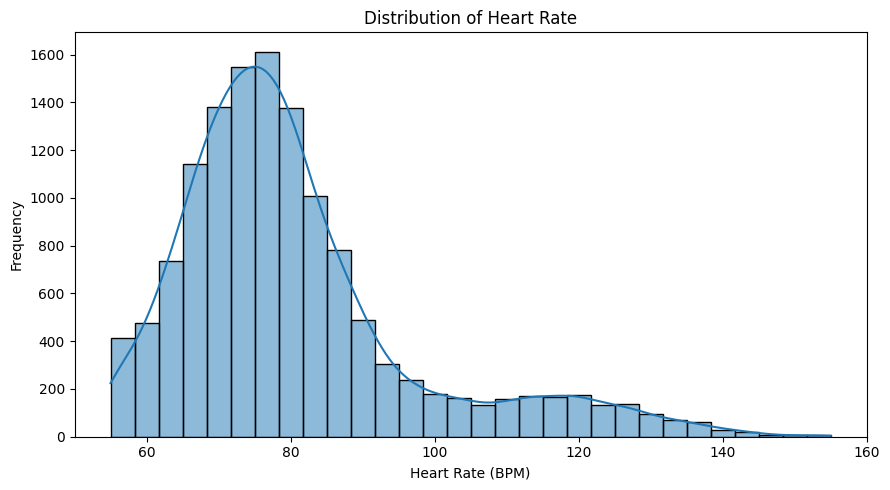

In [47]:
# Create a figure
plt.figure(figsize=(9, 5))

# Plot histogram with density curve
sns.histplot(
    df['heart_rate_bpm'],
    bins=30,
    kde=True
)

# Add chart title and labels
plt.title('Distribution of Heart Rate')
plt.xlabel('Heart Rate (BPM)')
plt.ylabel('Frequency')

# Display the chart
plt.tight_layout()
plt.show()

The heart-rate measurements have an average of approximately 81 bpm. The maximum value of 155 bpm indicates some considerably higher readings in the dataset.

7.Respiratory Rate Analysis
To understand the distribution and statistical characteristics of respiratory rate measurements.

In [48]:
# Calculate the statistical summary of respiratory rate
print(df['respiratory_rate_bpm'].describe())

count    13214.000000
mean        17.499213
std          4.131009
min         12.000000
25%         15.000000
50%         16.500000
75%         18.400000
max         39.200000
Name: respiratory_rate_bpm, dtype: float64


Histogram

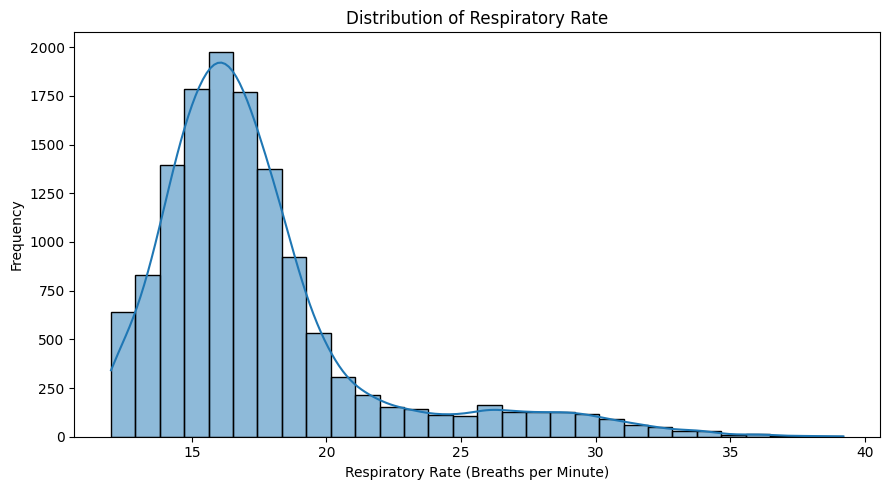

In [49]:
# Create a figure
plt.figure(figsize=(9, 5))

# Plot histogram with density curve
sns.histplot(
    df['respiratory_rate_bpm'],
    bins=30,
    kde=True
)

# Add chart title and labels
plt.title('Distribution of Respiratory Rate')
plt.xlabel('Respiratory Rate (Breaths per Minute)')
plt.ylabel('Frequency')

# Display the chart
plt.tight_layout()
plt.show()

The average respiratory rate is 17.50 breaths per minute. Some higher readings extend up to 39.2 breaths per minute.

8.Temperature Analysis
To examine the distribution and identify potential outliers in body temperature measurements.

In [50]:
# Calculate the statistical summary of body temperature
print(df['temperature_celsius'].describe())

count    13214.000000
mean        36.938527
std          0.728502
min         36.000000
25%         36.500000
50%         36.800000
75%         37.100000
max         40.400000
Name: temperature_celsius, dtype: float64


Box Plot

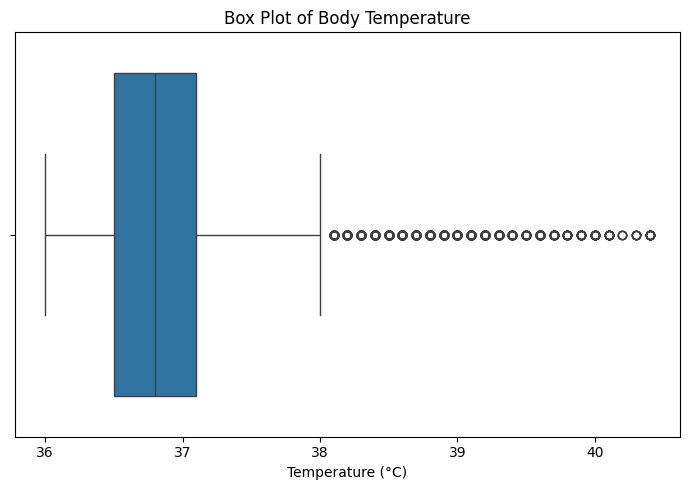

In [51]:
# Create a figure
plt.figure(figsize=(7, 5))

# Create box plot
sns.boxplot(x=df['temperature_celsius'])

# Add chart title and label
plt.title('Box Plot of Body Temperature')
plt.xlabel('Temperature (°C)')

# Display the chart
plt.tight_layout()
plt.show()

Most temperature readings are concentrated around 37°C. The box plot helps identify unusually high or low readings that may be potential outliers. These should be investigated rather than automatically removed.

9.SpO₂ Analysis

To understand the distribution of oxygen saturation measurements.

In [52]:
# Calculate the statistical summary of SpO2
print(df['spo2_percent'].describe())

count    13214.000000
mean        96.904208
std          3.347012
min         77.900000
25%         96.700000
50%         97.800000
75%         98.700000
max        100.000000
Name: spo2_percent, dtype: float64


Boxplot

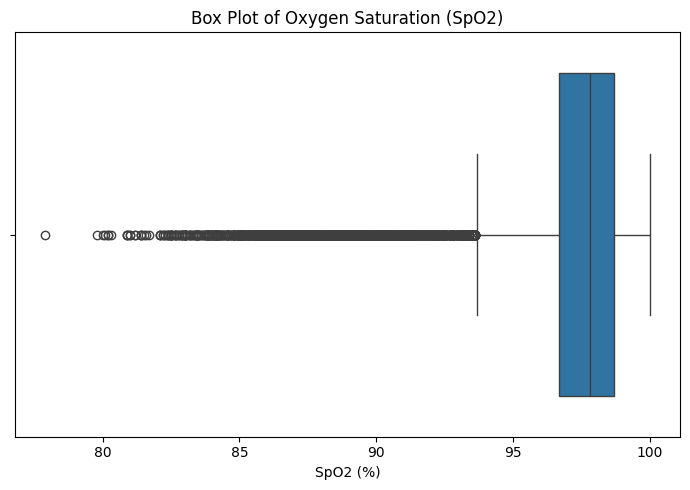

In [53]:
# Create a figure
plt.figure(figsize=(7, 5))

# Create box plot
sns.boxplot(x=df['spo2_percent'])

# Add chart title and label
plt.title('Box Plot of Oxygen Saturation (SpO2)')
plt.xlabel('SpO2 (%)')

# Display the chart
plt.tight_layout()
plt.show()

Most oxygen saturation readings are relatively high, with a median of 97.8%. The minimum value of 77.9% indicates some notably low readings that may require further investigation.

10.Blood Glucose Analysis

To understand the distribution and variation of blood glucose measurements.

In [54]:
# Calculate the statistical summary of blood glucose
print(df['blood_glucose_mg_dl'].describe())

count    13214.000000
mean       112.398138
std         38.371192
min         65.000000
25%         92.400000
50%        104.200000
75%        117.700000
max        349.200000
Name: blood_glucose_mg_dl, dtype: float64


Boxplot

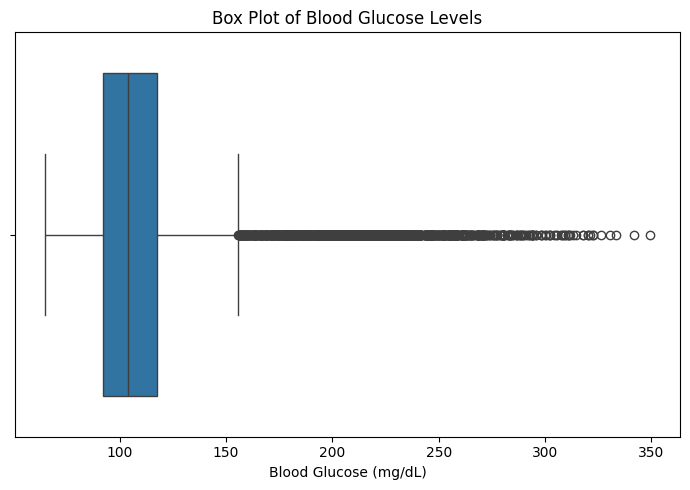

In [55]:
# Create a figure
plt.figure(figsize=(7, 5))

# Create box plot
sns.boxplot(x=df['blood_glucose_mg_dl'])

# Add chart title and label
plt.title('Box Plot of Blood Glucose Levels')
plt.xlabel('Blood Glucose (mg/dL)')

# Display the chart
plt.tight_layout()
plt.show()

Blood glucose values show considerable variation. The maximum reading of 349.2 mg/dL is much higher than the median, suggesting potential high-value outliers that deserve further investigation.

11.Serum Creatinine Analysis
To examine the distribution and variation of serum creatinine measurements.

In [56]:
# Calculate the statistical summary of serum creatinine
print(df['serum_creatinine_mg_dl'].describe())

count    13214.000000
mean         1.574806
std          0.821007
min          0.500000
25%          1.000000
50%          1.290000
75%          1.950000
max          7.500000
Name: serum_creatinine_mg_dl, dtype: float64


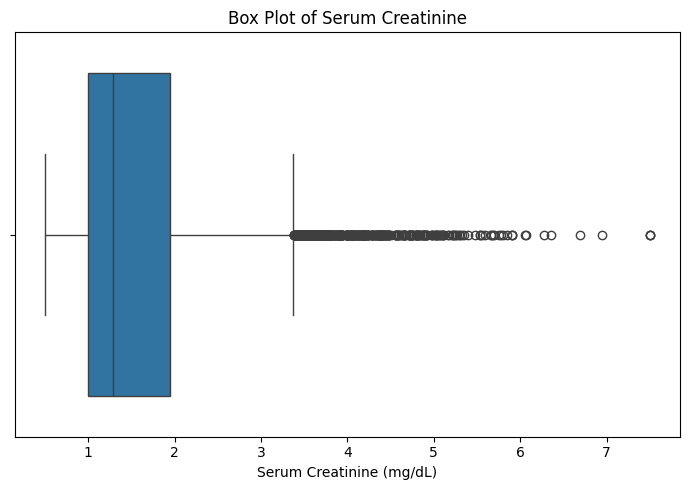

In [57]:
# Create a figure
plt.figure(figsize=(7, 5))

# Create box plot
sns.boxplot(x=df['serum_creatinine_mg_dl'])

# Add chart title and label
plt.title('Box Plot of Serum Creatinine')
plt.xlabel('Serum Creatinine (mg/dL)')

# Display the chart
plt.tight_layout()
plt.show()

Serum creatinine measurements show noticeable variation. The maximum value of 7.5 mg/dL is much higher than the median, indicating potential high-value outliers that should be investigated.

12.Hemoglobin Analysis
To understand the distribution and variation of hemoglobin measurements.

In [58]:
# Calculate the statistical summary of hemoglobin
print(df['hemoglobin_g_dl'].describe())

count    13214.000000
mean        13.092901
std          1.978711
min          6.500000
25%         11.900000
50%         13.300000
75%         14.400000
max         17.500000
Name: hemoglobin_g_dl, dtype: float64


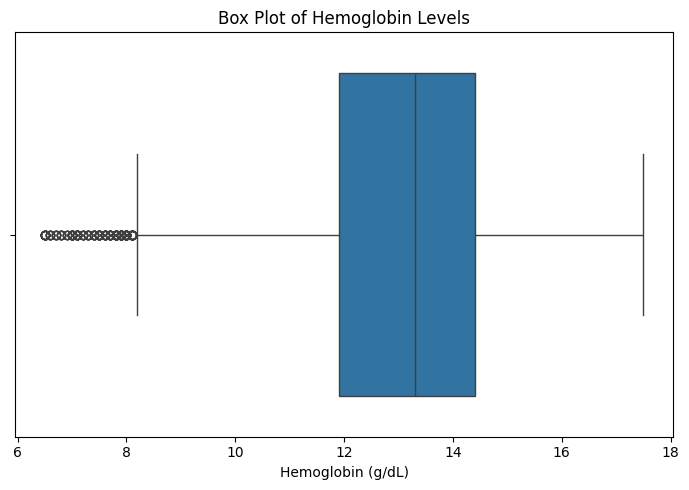

In [59]:
# Create a figure
plt.figure(figsize=(7, 5))

# Create box plot
sns.boxplot(x=df['hemoglobin_g_dl'])

# Add chart title and label
plt.title('Box Plot of Hemoglobin Levels')
plt.xlabel('Hemoglobin (g/dL)')

# Display the chart
plt.tight_layout()
plt.show()

Hemoglobin measurements are centred around 13 g/dL. The minimum value of 6.5 g/dL is considerably lower than the median and may appear as a potential low-value outlier.

13.White Blood Cell (WBC) Analysis
To examine the distribution and variation of white blood cell count

In [60]:
# Calculate the statistical summary of WBC count
print(df['white_blood_cell_count'].describe())

count    13214.000000
mean        10.977115
std          5.586824
min          3.200000
25%          7.000000
50%          8.700000
75%         15.000000
max         31.000000
Name: white_blood_cell_count, dtype: float64


Boxplot

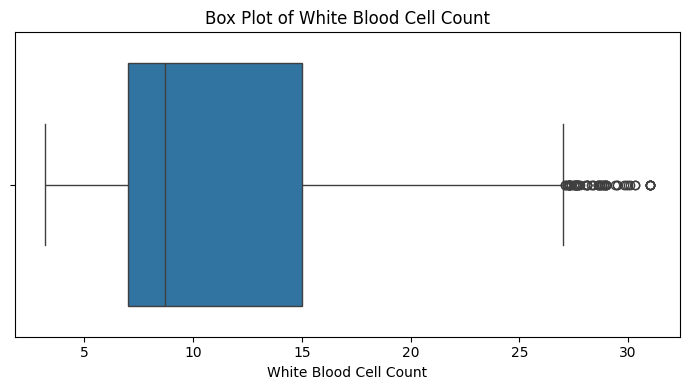

In [61]:
# Create a figure
plt.figure(figsize=(7, 4))

# Create box plot
sns.boxplot(x=df['white_blood_cell_count'])

# Add chart title and label
plt.title('Box Plot of White Blood Cell Count')
plt.xlabel('White Blood Cell Count')

# Display the chart
plt.tight_layout()
plt.show()

The average WBC count is approximately 10.98, while the median is 8.70. The maximum value is 31, indicating some considerably higher readings. The box plot helps identify potential outliers that may need further investigation.

14.Correlation Analysis

To identify relationships between numerical variables in the healthcare dataset.

In [62]:
# Calculate correlation between numerical columns
correlation = df.corr(numeric_only=True)

# Display the correlation values
print(correlation)

                             systolic_bp_mmhg  diastolic_bp_mmhg  \
systolic_bp_mmhg                     1.000000           0.947524   
diastolic_bp_mmhg                    0.947524           1.000000   
heart_rate_bpm                      -0.380378          -0.361060   
respiratory_rate_bpm                -0.433271          -0.411535   
temperature_celsius                 -0.501351          -0.473390   
spo2_percent                         0.460622           0.434077   
blood_glucose_mg_dl                 -0.016361          -0.015957   
serum_creatinine_mg_dl              -0.108245          -0.101076   
hemoglobin_g_dl                      0.307967           0.293073   
white_blood_cell_count              -0.189934          -0.179378   
hospital_acquired_infection         -0.042355          -0.037944   

                             heart_rate_bpm  respiratory_rate_bpm  \
systolic_bp_mmhg                  -0.380378             -0.433271   
diastolic_bp_mmhg                 -0.361060  

Correlation Heatmap

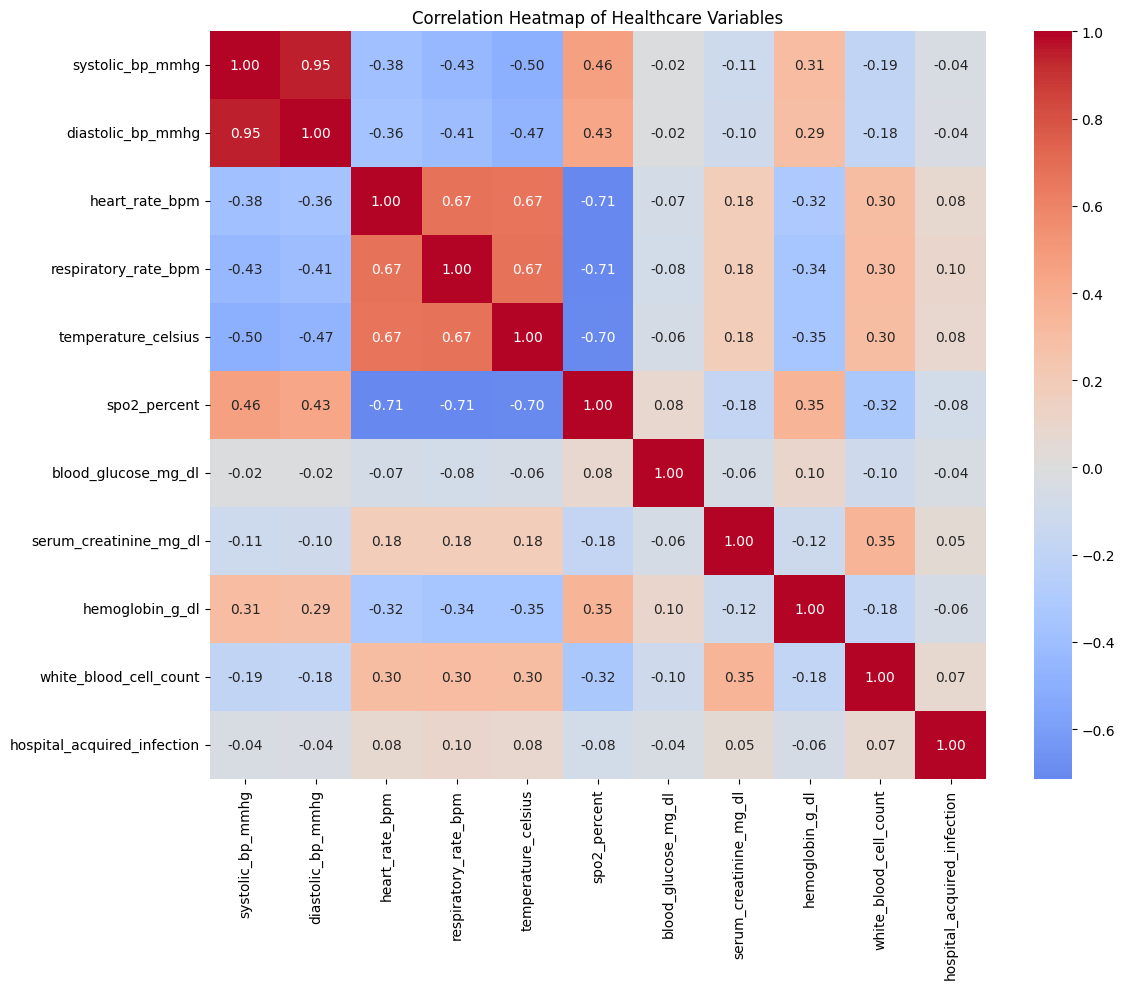

In [63]:
# Set the figure size
plt.figure(figsize=(12, 10))

# Create the correlation heatmap
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

# Add chart title
plt.title('Correlation Heatmap of Healthcare Variables')

# Display the chart
plt.tight_layout()
plt.show()

The correlation heatmap highlights several relationships between healthcare variables:

- Systolic and diastolic blood pressure have a strong positive correlation.
- Heart rate and respiratory rate show a positive correlation.
- Heart rate and SpO₂ show a negative correlation.
- Temperature and respiratory rate show a positive correlation.
- Some variables, such as blood glucose and blood pressure, have very weak correlations.
These relationships help us understand how different clinical measurements vary together. They do not establish cause and effect.

15.Procedure Complexity Analysis

To understand how frequently each procedure complexity category appears in the dataset.

In [64]:
# Count records in each procedure complexity category
procedure_counts = df['procedure_complexity'].value_counts()

# Display the counts
print(procedure_counts)

procedure_complexity
Not Applicable     5654
Moderate           3270
Major              2612
High-Complexity     875
Minor               803
Name: count, dtype: int64


Barchart

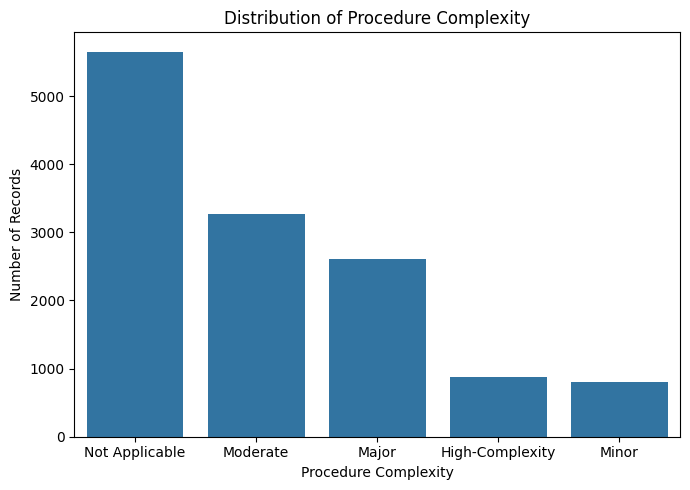

In [65]:
# Set figure size
plt.figure(figsize=(7, 5))

# Create bar chart
sns.barplot(
    x=procedure_counts.index,
    y=procedure_counts.values
)

# Add title and labels
plt.title('Distribution of Procedure Complexity')
plt.xlabel('Procedure Complexity')
plt.ylabel('Number of Records')

# Display chart
plt.tight_layout()
plt.show()

The bar chart shows that Not Applicable is the largest category, with 5,654 records, followed by Moderate and Major. Minor procedures have the fewest records.

 16.Disease Severity Across Disease Categories

 To identify which disease categories have a higher representation of Mild, Moderate, Severe, and Critical cases.

In [66]:
# Create a cross-tabulation of disease category and severity
severity_by_disease = pd.crosstab(
    df['disease_category'],
    df['disease_severity']
)

# Display the results
print(severity_by_disease)

disease_severity  Critical  Mild  Moderate  Severe
disease_category                                  
Cardiovascular         281   199       814     763
Endocrine               34   506       586     165
Gastrointestinal        34   419       622     228
Infectious             675     0       235     755
Musculoskeletal          0   277       426     136
Obstetrics               0   207        83      12
Oncology               181    88       265     341
Pediatrics               1   190        92      30
Renal                   26   691       561     157
Respiratory            160   567      1198     573
Trauma                 101    37       222     276


Infectious diseases have a particularly high number of Critical cases (675), while Oncology and Trauma have more Severe cases than other severity levels.

Stacked Barchart

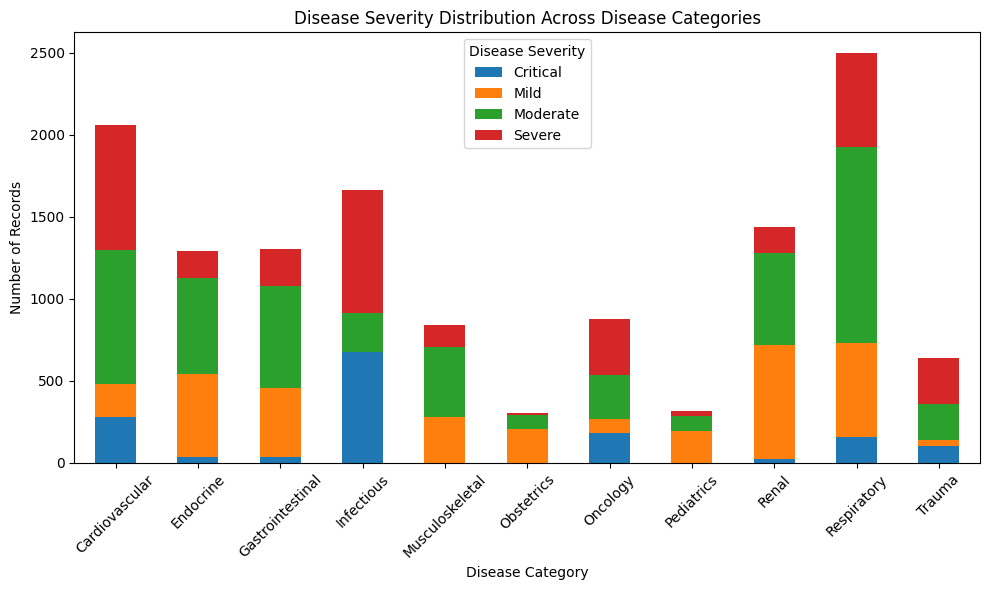

In [67]:
# Create a stacked bar chart
severity_by_disease.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

# Add title and axis labels
plt.title('Disease Severity Distribution Across Disease Categories')
plt.xlabel('Disease Category')
plt.ylabel('Number of Records')

# Adjust layout
plt.xticks(rotation=45)
plt.legend(title='Disease Severity')
plt.tight_layout()
plt.show()

The stacked bar chart  compare the number of Mild, Moderate, Severe, and Critical records across disease categories.

17.Compare Disease Severity by Percentage

Help to compare disease categories fairly, even when their total record counts differ.

In [68]:
# Calculate severity percentages within each disease category
severity_percentage = pd.crosstab(
    df['disease_category'],
    df['disease_severity'],
    normalize='index'
) * 100

# Display percentages rounded to 2 decimal places
print(severity_percentage.round(2))

disease_severity  Critical   Mild  Moderate  Severe
disease_category                                   
Cardiovascular       13.66   9.67     39.57   37.09
Endocrine             2.63  39.19     45.39   12.78
Gastrointestinal      2.61  32.16     47.74   17.50
Infectious           40.54   0.00     14.11   45.35
Musculoskeletal       0.00  33.02     50.77   16.21
Obstetrics            0.00  68.54     27.48    3.97
Oncology             20.69  10.06     30.29   38.97
Pediatrics            0.32  60.70     29.39    9.58
Renal                 1.81  48.15     39.09   10.94
Respiratory           6.41  22.70     47.96   22.94
Trauma               15.88   5.82     34.91   43.40


The percentage distribution reveals differences in disease severity patterns that were less obvious when comparing absolute counts.

Stacked Barchart

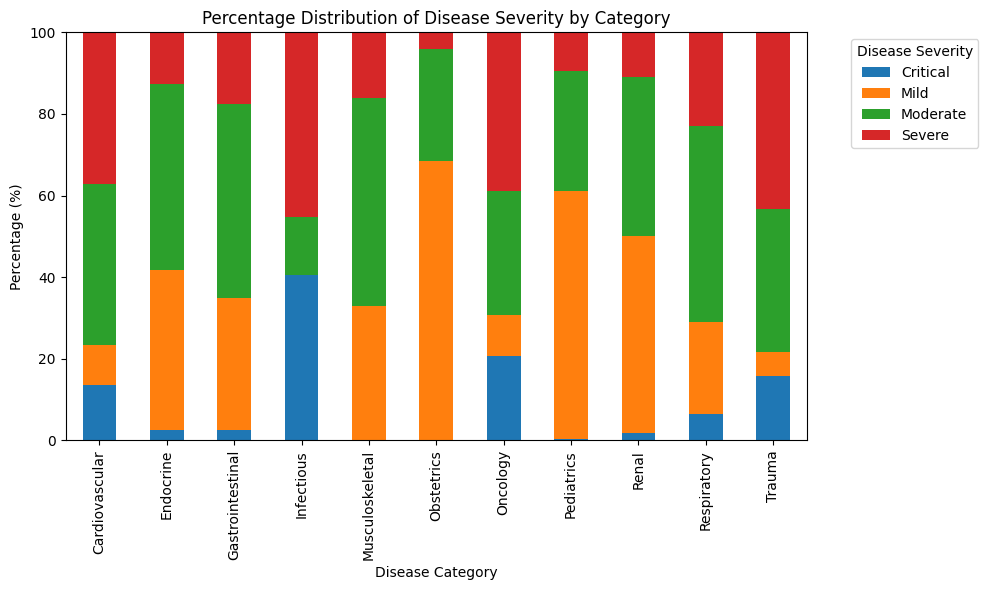

In [69]:
# Create a 100% stacked bar chart
severity_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

# Add chart title and labels
plt.title('Percentage Distribution of Disease Severity by Category')
plt.xlabel('Disease Category')
plt.ylabel('Percentage (%)')

# Set y-axis range
plt.ylim(0, 100)

# Add legend
plt.legend(title='Disease Severity', bbox_to_anchor=(1.05, 1))

# Display chart
plt.tight_layout()
plt.show()

The 100% stacked bar chart makes it easier to compare disease severity proportions across categories, regardless of the number of records in each category.

18.Hospital-Acquired Infection Analysis by Disease Category

 To Identify which disease categories have higher numbers and proportions of records marked with hospital-acquired infection.

In [70]:
# Create a cross-tabulation of disease category and hospital-acquired infection
infection_by_disease = pd.crosstab(
    df['disease_category'],
    df['hospital_acquired_infection']
)

# Display the results
print(infection_by_disease)

hospital_acquired_infection     0    1
disease_category                      
Cardiovascular               1987   70
Endocrine                    1284    7
Gastrointestinal             1286   17
Infectious                   1559  106
Musculoskeletal               822   17
Obstetrics                    301    1
Oncology                      837   38
Pediatrics                    309    4
Renal                        1412   23
Respiratory                  2463   35
Trauma                        592   44


19.Infection Percentage by Disease Category

To Calculate the percentage of records marked with hospital-acquired infection within each disease category.

In [71]:
# Calculate infection percentage within each disease category
infection_percentage = pd.crosstab(
    df['disease_category'],
    df['hospital_acquired_infection'],
    normalize='index'
) * 100

# Display infection percentages
print(infection_percentage.round(2))

hospital_acquired_infection      0     1
disease_category                        
Cardiovascular               96.60  3.40
Endocrine                    99.46  0.54
Gastrointestinal             98.70  1.30
Infectious                   93.63  6.37
Musculoskeletal              97.97  2.03
Obstetrics                   99.67  0.33
Oncology                     95.66  4.34
Pediatrics                   98.72  1.28
Renal                        98.40  1.60
Respiratory                  98.60  1.40
Trauma                       93.08  6.92


Infection Percentage by Disease Category
Horizontal Barchart

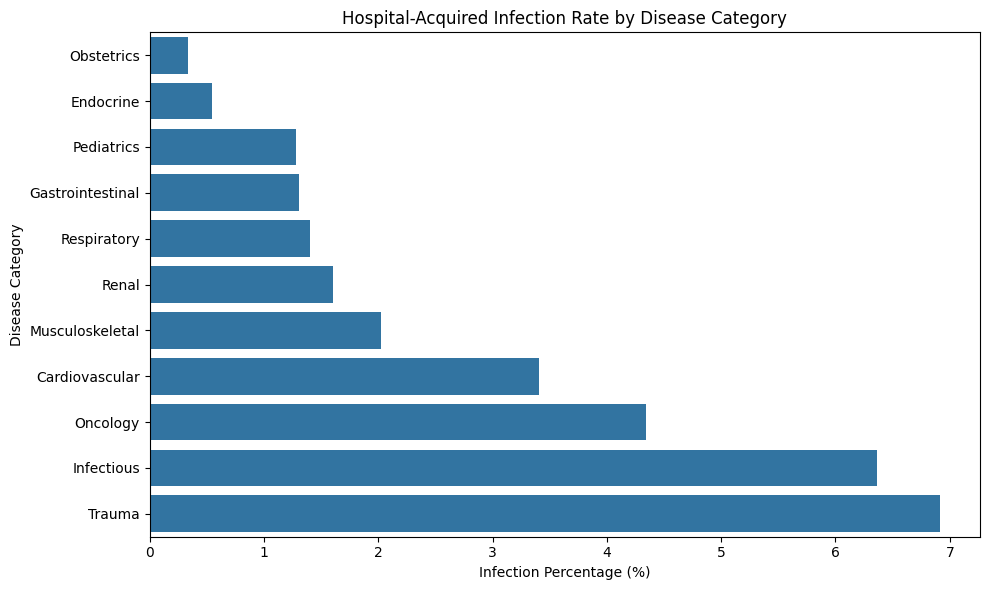

In [72]:
# Extract infection percentages (1 = infection recorded)
infection_rate = infection_percentage[1].sort_values(ascending=True)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=infection_rate.values, y=infection_rate.index)

# Add title and labels
plt.title('Hospital-Acquired Infection Rate by Disease Category')
plt.xlabel('Infection Percentage (%)')
plt.ylabel('Disease Category')

plt.tight_layout()
plt.show()

The horizontal bar chart highlights differences in hospital-acquired infection percentages across disease categories.
- Trauma has the highest recorded infection proportion (6.92%).
- Infectious follows at 6.37%.
- Oncology records 4.34%.
- Obstetrics has the lowest proportion (0.33%).

20.Relationship Between Procedure Complexity and Disease Severity

To examine how disease severity is distributed across different procedure complexity categories.

In [73]:
# Create a cross-tabulation of procedure complexity and disease severity
procedure_severity = pd.crosstab(
    df['procedure_complexity'],
    df['disease_severity']
)

# Display the results
print(procedure_severity)

disease_severity      Critical  Mild  Moderate  Severe
procedure_complexity                                  
High-Complexity            181    88       265     341
Major                      303   366      1056     887
Minor                       81   161       336     225
Moderate                   709   626       940     995
Not Applicable             219  1940      2507     988


In [74]:
# Calculate severity percentages within each procedure complexity category
procedure_severity_percentage = pd.crosstab(
    df['procedure_complexity'],
    df['disease_severity'],
    normalize='index'
) * 100

# Display percentages rounded to 2 decimal places
print(procedure_severity_percentage.round(2))

disease_severity      Critical   Mild  Moderate  Severe
procedure_complexity                                   
High-Complexity          20.69  10.06     30.29   38.97
Major                    11.60  14.01     40.43   33.96
Minor                    10.09  20.05     41.84   28.02
Moderate                 21.68  19.14     28.75   30.43
Not Applicable            3.87  34.31     44.34   17.47


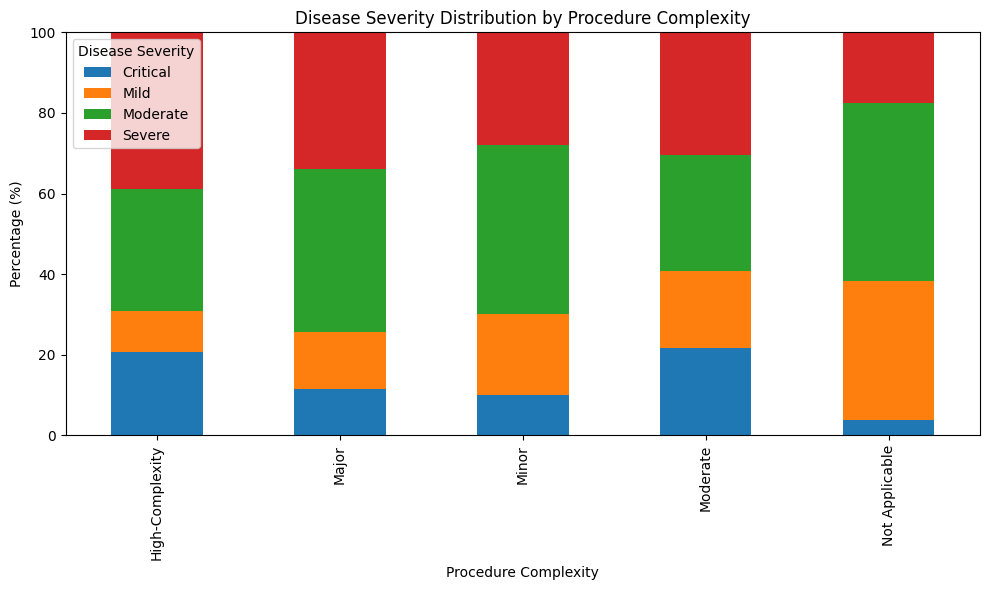

In [75]:
# Create a 100% stacked bar chart
procedure_severity_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

# Add chart title and labels
plt.title('Disease Severity Distribution by Procedure Complexity')
plt.xlabel('Procedure Complexity')
plt.ylabel('Percentage (%)')

# Set percentage scale
plt.ylim(0, 100)

# Add legend
plt.legend(title='Disease Severity')

# Display chart
plt.tight_layout()
plt.show()

The 100% stacked bar chart highlights differences in disease severity distribution across procedure complexity categories.